Technological Institute of the Philippines | Quezon City - Computer Engineering
--- | ---
Course Code: | CPE 027
Code Title: | Digital Signal Processing and Application
1st Semester | AY 2026-2027
<u>**Laboratory Activity 3** | **Statistical Analysis of Signals**
**Name** | Adrian Justin Bulambao
**Section** | CPE41S1
**Date Performed**: | July 31, 2026
**Date Submitted**: | July 31, 2026
**Instructor**: | Engr. Ji Han Gang

<hr>


A sensor managed to sample data in 0 to 195 steps. You will be given access to a repository of each sample in the form of CSV files. Use only csv files coming from machine B1. There is a total of 196 sample files, each of those files contain 41,666 data points. Disregard the file labeled: Base Noise.

1. Create a program that can calculate the mean, standard deviation, and standard error of voltage and resistance for each STEP, and consolidate it in a separate (new) csv file.

In [ ]:
import glob
import os
import pandas as pd

path = "/content/drive/MyDrive/dataset for kids"
all_csv_files = glob.glob(os.path.join(path, "*.csv"))
filtered_files = [
    f
    for f in all_csv_files
    if f.endswith("B1.csv") and "BaseNoise_B1" not in os.path.basename(f)
]
rows_list = []

for step in filtered_files:
    # Load the CSV
    data = pd.read_csv(step, header=4)

    # Calculate stats using 'data', and create a simple dictionary
    new_row = {
        'Mean_V': data['AE [V]'].mean(),
        'Std_V' : data['AE [V]'].std(),
        'Ste_V' : data['AE [V]'].sem(),
        'Mean_R': data['TDS-DC [Ohm]'].mean(),
        'Std_R' : data['TDS-DC [Ohm]'].std(),
        'Ste_R' : data['TDS-DC [Ohm]'].sem()
    }

    # Append the dictionary to our list
    rows_list.append(new_row)

# 2. Convert the entire list of rows into the final DataFrame at once
summarized_data = pd.DataFrame(rows_list)
print(summarized_data)
summarized_data.to_csv('summarized_data.csv',index=False)

       Mean_V     Std_V     Ste_V  Mean_R  Std_R  Ste_R
0   -0.000716  0.090595  0.000444     0.0    0.0    0.0
1   -0.000689  0.419071  0.002053     0.0    0.0    0.0
2   -0.000083  0.066024  0.000323     0.0    0.0    0.0
3   -0.000581  0.065782  0.000322     0.0    0.0    0.0
4   -0.000519  0.065436  0.000321     0.0    0.0    0.0
..        ...       ...       ...     ...    ...    ...
191 -0.000743  0.565616  0.002771     0.0    0.0    0.0
192 -0.000237  0.063927  0.000313     0.0    0.0    0.0
193 -0.000261  0.143190  0.000701     0.0    0.0    0.0
194 -0.000513  0.129388  0.000634     0.0    0.0    0.0
195 -0.000680  0.136055  0.000667     0.0    0.0    0.0

[196 rows x 6 columns]


2. Then plot the resulted new csv file that shows the mean, standard deviation, and standard error of voltage and resistance for each STEP

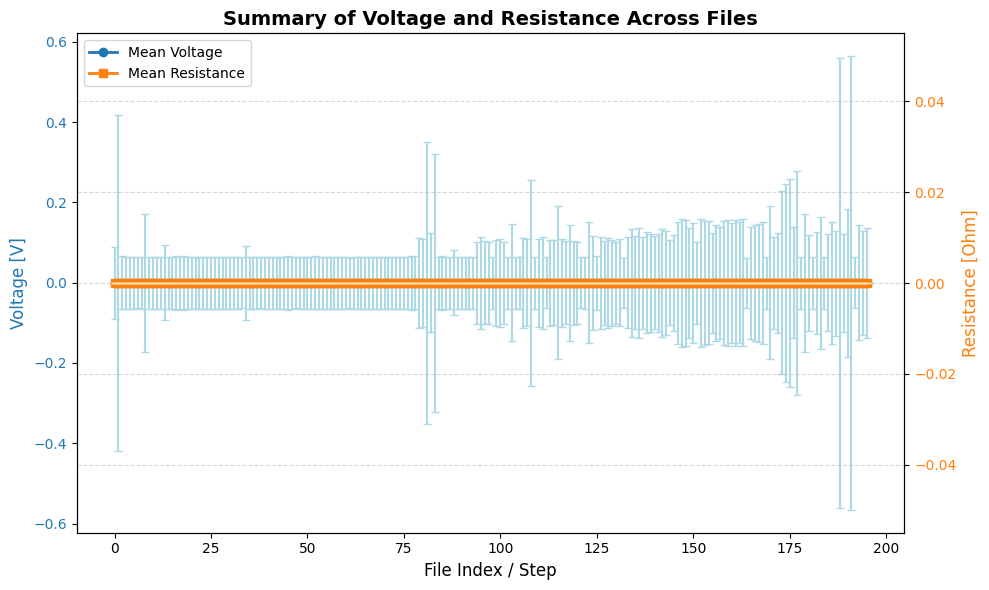

In [ ]:
import matplotlib.pyplot as plt

# Create the plot and the first axis (Left Y-axis for Voltage)
fig, ax1 = plt.subplots(figsize=(10, 6))

# Plot Mean Voltage
color = 'tab:blue'
ax1.set_xlabel('File Index / Step', fontsize=12)
ax1.set_ylabel('Voltage [V]', color=color, fontsize=12)
line1 = ax1.plot(summarized_data.index, summarized_data['Mean_V'], color=color, marker='o', linewidth=2, label='Mean Voltage')
ax1.tick_params(axis='y', labelcolor=color)

# Add error bars for Voltage standard deviation (optional, but good practice)
ax1.errorbar(summarized_data.index, summarized_data['Mean_V'], yerr=summarized_data['Std_V'], fmt='none', ecolor='lightblue', capsize=3)

# Create a second axis that shares the same x-axis (Right Y-axis for Resistance)
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Resistance [Ohm]', color=color, fontsize=12)
line2 = ax2.plot(summarized_data.index, summarized_data['Mean_R'], color=color, marker='s', linewidth=2, label='Mean Resistance')
ax2.tick_params(axis='y', labelcolor=color)

# Add error bars for Resistance standard deviation (optional)
ax2.errorbar(summarized_data.index, summarized_data['Mean_R'], yerr=summarized_data['Std_R'], fmt='none', ecolor='moccasin', capsize=3)

# Combine legends from both axes
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.title('Summary of Voltage and Resistance Across Files', fontsize=14, fontweight='bold')
plt.grid(True, linestyle='--', alpha=0.5)

# Display the plot
plt.tight_layout()
plt.show()

3. Create a program that is able to plot the time-series plots of G1_Hd1_FTDS_SP1_050418_162003_1_0_0_B1.csv

In [ ]:
B1_step1 = pd.read_csv('/content/drive/MyDrive/dataset for kids/G1_Hd1_FTDS_SP1_050418_162003_1_0_0_B1.csv', header=4)
B1_step1.head()

,Time [sec],AE [V],TDS-DC [Ohm],Unnamed: 3
0,0.000000e+00,-0.104980,0.0,NaN
1,2.000000e-07,-0.053711,0.0,NaN
2,4.000000e-07,-0.024414,0.0,NaN
3,6.000000e-07,-0.029297,0.0,NaN
4,8.000000e-07,-0.041504,0.0,NaN


In [ ]:
B1_step1 = B1_step1.drop(columns='Unnamed: 3')
B1_step1.head()

,Time [sec],AE [V],TDS-DC [Ohm]
0,0.000000e+00,-0.104980,0.0
1,2.000000e-07,-0.053711,0.0
2,4.000000e-07,-0.024414,0.0
3,6.000000e-07,-0.029297,0.0
4,8.000000e-07,-0.041504,0.0


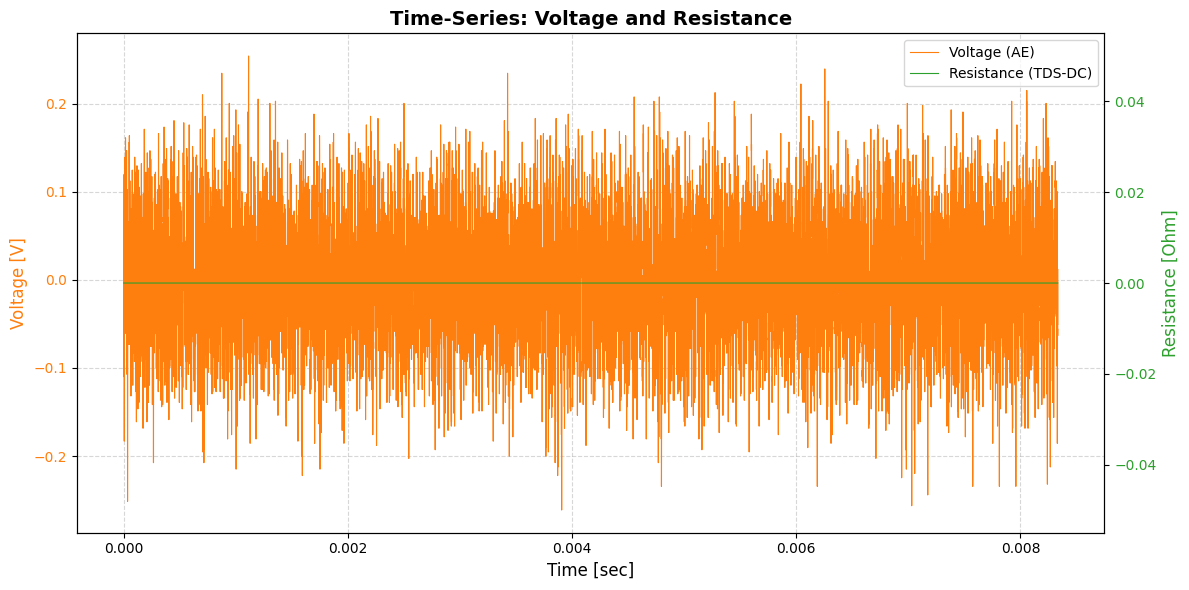

In [ ]:
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Voltage on the primary (left) Y-axis
line1 = ax1.plot(B1_step1['Time [sec]'], B1_step1['AE [V]'], color='tab:orange', linewidth=0.8, label='Voltage (AE)')
ax1.set_xlabel('Time [sec]', fontsize=12)
ax1.set_ylabel('Voltage [V]', color='tab:orange', fontsize=12)
ax1.tick_params(axis='y', labelcolor='tab:orange')
ax1.grid(True, linestyle='--', alpha=0.5)

# Create a twin axis sharing the same X-axis for Resistance (right Y-axis)
ax2 = ax1.twinx()
line2 = ax2.plot(B1_step1['Time [sec]'], B1_step1['TDS-DC [Ohm]'], color='tab:green', linewidth=0.8, label='Resistance (TDS-DC)')
ax2.set_ylabel('Resistance [Ohm]', color='tab:green', fontsize=12)
ax2.tick_params(axis='y', labelcolor='tab:green')

# Combine the legends from both axes into a single legend box
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right', fontsize=10)

# Set the overall title
plt.title('Time-Series: Voltage and Resistance', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

4. Also, plot the histogram of voltage and resistance of G1_Hd1_FTDS_SP1_050418_162003_1_0_0_B1.csv for its first 1500 samples. Then try 8000 samples, then 25000 samples, and lastly, all samples.

In [ ]:
B1_step1[:1500].head()

,Time [sec],AE [V],TDS-DC [Ohm]
0,0.000000e+00,-0.104980,0.0
1,2.000000e-07,-0.053711,0.0
2,4.000000e-07,-0.024414,0.0
3,6.000000e-07,-0.029297,0.0
4,8.000000e-07,-0.041504,0.0


In [ ]:
B1_step1[:1500].tail()

,Time [sec],AE [V],TDS-DC [Ohm]
1495,0.000299,-0.070801,0.0
1496,0.000299,-0.083008,0.0
1497,0.000299,-0.085449,0.0
1498,0.000300,-0.090332,0.0
1499,0.000300,-0.073242,0.0


In [ ]:
first_sample = B1_step1[:1500]
first_sample.columns

Index(['Time [sec]', 'AE [V]', 'TDS-DC [Ohm]'], dtype='object')

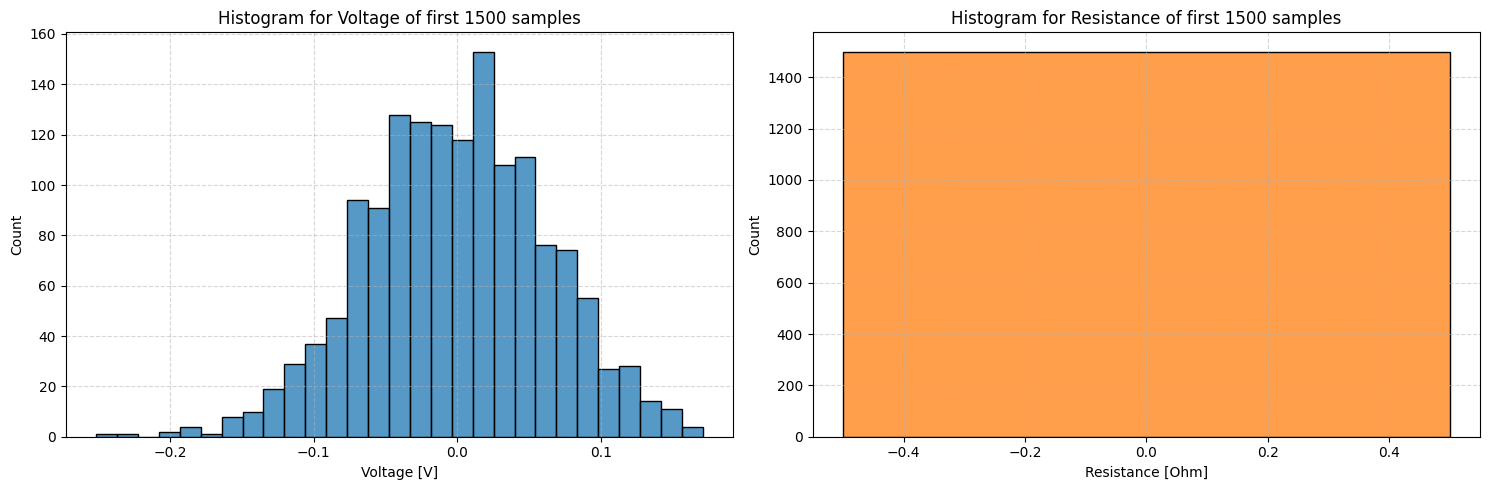

In [ ]:
import seaborn as sns

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# voltage
sns.histplot(data=first_sample['AE [V]'], ax=ax1, color='tab:blue')
ax1.set_title('Histogram for Voltage of first 1500 samples', fontsize=12)
ax1.set_xlabel('Voltage [V]')
ax1.set_ylabel('Count')
ax1.grid(True, linestyle='--', alpha=0.5)

# resistance
sns.histplot(data=first_sample['TDS-DC [Ohm]'], ax=ax2, color='tab:orange')
ax2.set_title('Histogram for Resistance of first 1500 samples', fontsize=12)
ax2.set_xlabel('Resistance [Ohm]')
ax2.set_ylabel('Count')
ax2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

### <b> Checking for 8000 samples

In [ ]:
second_sample = B1_step1[:8000]
second_sample.columns

Index(['Time [sec]', 'AE [V]', 'TDS-DC [Ohm]'], dtype='object')

In [ ]:
second_sample.tail()

,Time [sec],AE [V],TDS-DC [Ohm]
7995,0.001599,0.021973,0.0
7996,0.001599,0.012207,0.0
7997,0.001599,0.041504,0.0
7998,0.001600,0.056152,0.0
7999,0.001600,0.058594,0.0


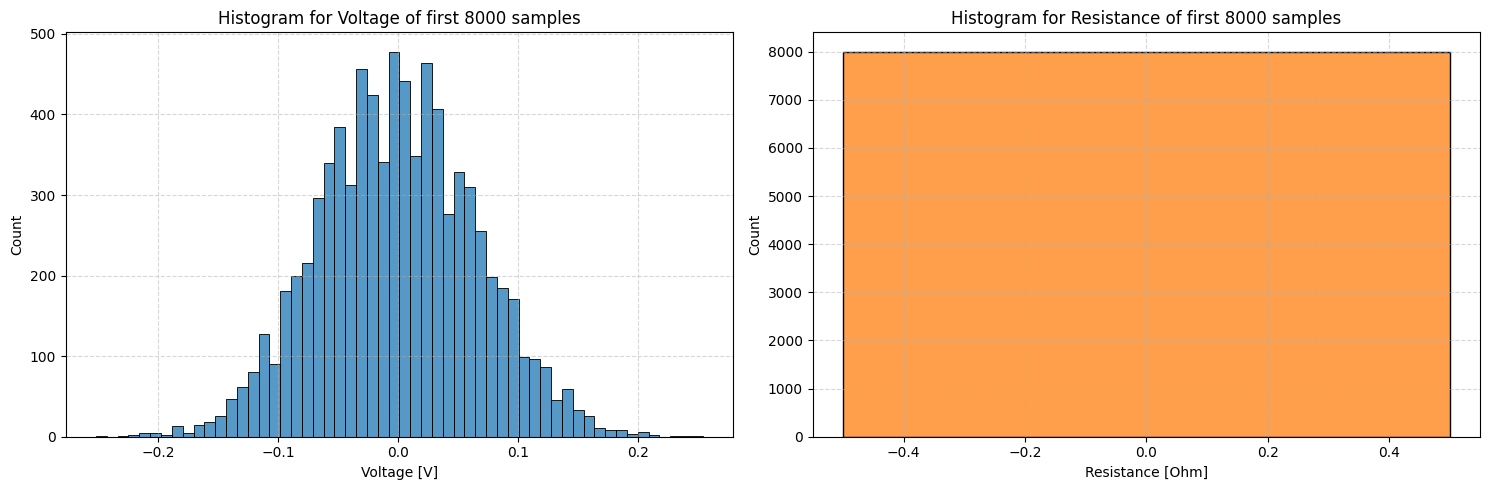

In [ ]:


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# voltage
sns.histplot(data=second_sample['AE [V]'], ax=ax1, color='tab:blue')
ax1.set_title('Histogram for Voltage of first 8000 samples', fontsize=12)
ax1.set_xlabel('Voltage [V]')
ax1.set_ylabel('Count')
ax1.grid(True, linestyle='--', alpha=0.5)

# resistance
sns.histplot(data=second_sample['TDS-DC [Ohm]'], ax=ax2, color='tab:orange')
ax2.set_title('Histogram for Resistance of first 8000 samples', fontsize=12)
ax2.set_xlabel('Resistance [Ohm]')
ax2.set_ylabel('Count')
ax2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

### <b> Checking for 25000 samples

In [ ]:
third_sample = B1_step1[:25000]
third_sample.columns

Index(['Time [sec]', 'AE [V]', 'TDS-DC [Ohm]'], dtype='object')

In [ ]:
third_sample.tail()

,Time [sec],AE [V],TDS-DC [Ohm]
24995,0.004999,-0.041504,0.0
24996,0.004999,-0.029297,0.0
24997,0.004999,0.007324,0.0
24998,0.005000,0.041504,0.0
24999,0.005000,0.048828,0.0


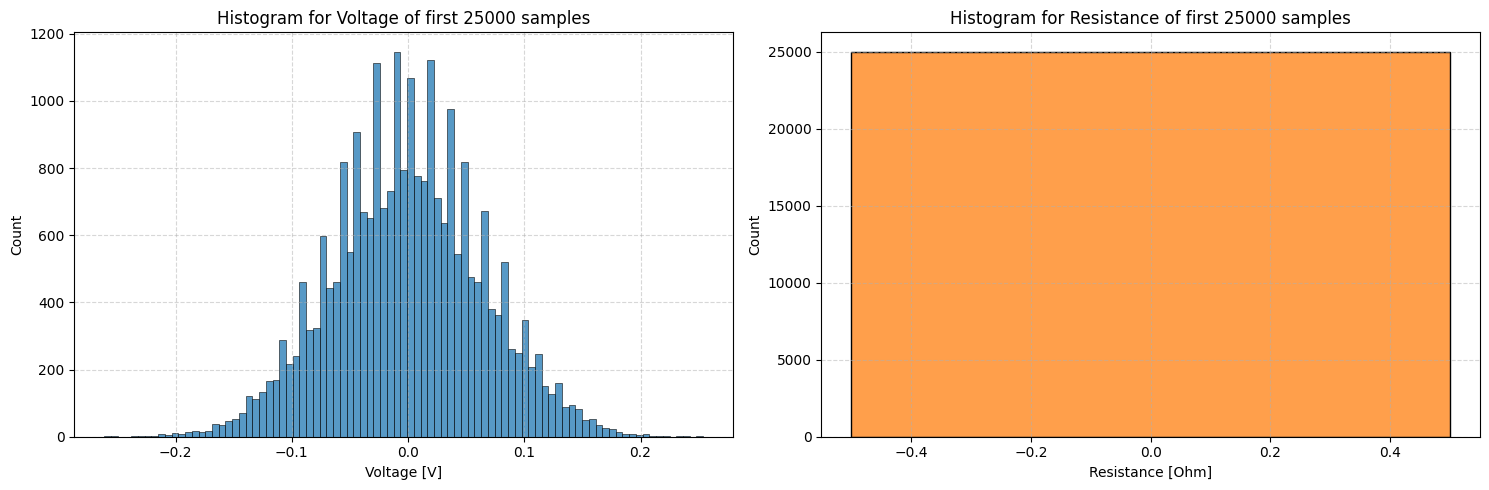

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# voltage
sns.histplot(data=third_sample['AE [V]'], ax=ax1, color='tab:blue')
ax1.set_title('Histogram for Voltage of first 25000 samples', fontsize=12)
ax1.set_xlabel('Voltage [V]')
ax1.set_ylabel('Count')
ax1.grid(True, linestyle='--', alpha=0.5)

# resistance
sns.histplot(data=third_sample['TDS-DC [Ohm]'], ax=ax2, color='tab:orange')
ax2.set_title('Histogram for Resistance of first 25000 samples', fontsize=12)
ax2.set_xlabel('Resistance [Ohm]')
ax2.set_ylabel('Count')
ax2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()

### <b> All Samples

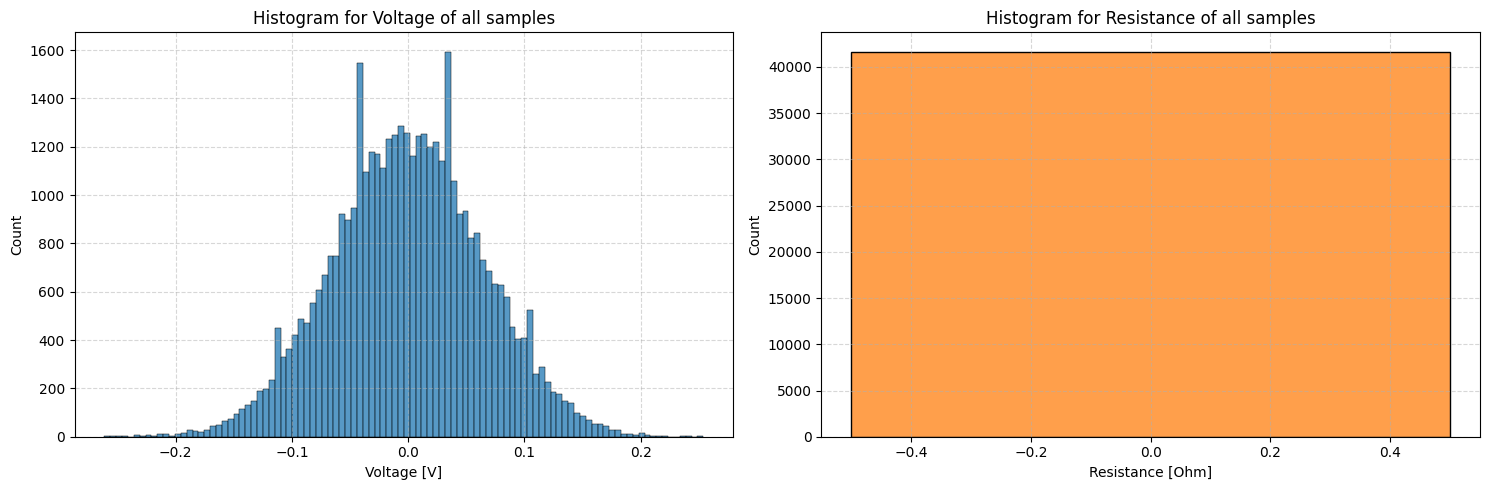

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# voltage
sns.histplot(data=B1_step1['AE [V]'], ax=ax1, color='tab:blue')
ax1.set_title('Histogram for Voltage of all samples', fontsize=12)
ax1.set_xlabel('Voltage [V]')
ax1.set_ylabel('Count')
ax1.grid(True, linestyle='--', alpha=0.5)

# resistance
sns.histplot(data=B1_step1['TDS-DC [Ohm]'], ax=ax2, color='tab:orange')
ax2.set_title('Histogram for Resistance of all samples', fontsize=12)
ax2.set_xlabel('Resistance [Ohm]')
ax2.set_ylabel('Count')
ax2.grid(True, linestyle='--', alpha=0.5)


plt.tight_layout()
plt.show()